# 第10章　実問題への適用

第1〜9章の合成材料に保持時間を加えます。温度140〜180 °C、保持時間10〜40分の範囲で、強度 [MPa] を高める設定を検討します。合成データで、過去ログの取込、失敗の保存、候補提案、結果の更新、独立した確認測定を通して実行します。

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import torch
from robotorchan.models import SingleTaskGP
from robotorchan.study import TrialState

from experiment import BLUE, DTYPE, GREEN, INK, ORANGE, QUALITY, ROOT, SEED, save_figure, setup
from production_experiment import (
    BOUNDS, BOX, INPUTS, historical_log, measure, model_transforms, new_study, register_history,
)

setup()
torch.set_default_dtype(DTYPE)
data = ROOT / "data"
data.mkdir(exist_ok=True)
source = data / "ch10_historical_log.csv"
historical_log().to_csv(source, index=False)
history = pd.read_csv(source, keep_default_na=False, na_values={"strength_mpa": [""]})
study = new_study()
metadata = register_history(study, history)

complete_history = study.trials_dataframe(states=(TrialState.COMPLETE,))
assert len(complete_history) == 8
failed = study.trials_dataframe(states=(TrialState.FAIL,))
assert len(failed) == 1 and failed["value"].isna().all()
print(history.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

experiment_id   lot  temperature_c  hold_min   status  strength_mpa failure_reason
          H01 SIM-A         140.00     10.00 COMPLETE         73.77               
          H02 SIM-A         144.00     34.00 COMPLETE         77.13               
          H03 SIM-A         149.00     17.00 COMPLETE         81.18               
          H04 SIM-A         152.00     33.00 COMPLETE         78.51               
          H05 SIM-A         156.00     24.00 COMPLETE         82.05               
          H06 SIM-A         162.00     13.00     FAIL           NaN   模擬計測器のタイムアウト
          H07 SIM-A         168.00     29.00 COMPLETE         60.41               
          H08 SIM-A         175.00     37.00 COMPLETE         65.42               
          H09 SIM-A         180.00     22.00 COMPLETE         81.29               


## 10.2 過去の試験から次の条件を提案する

BOを始める閾値は完了5件で、過去8件の取込後は最初の `ask` から学習済みGPを使います。新しい3件は1件ずつ提案・測定・登録します。合成の測定機器は別seedを使っています。現場では測定の代わりに、提案したIDの結果が戻るまで待ちます。

In [2]:
generator = torch.Generator().manual_seed(SEED + 101)
for i in range(3):
    running = study.ask()
    setting = torch.tensor([running.params[name] for name in INPUTS], dtype=DTYPE)
    observed = float(measure(setting, generator))
    study.tell(running, observed)
    metadata.loc[len(metadata)] = [running.number, f"B{i + 1:02d}", "SIM-A", ""]

results = study.trials_dataframe()
audit_log = results.merge(metadata, on="number", validate="one_to_one", how="left")
assert len(audit_log) == 12 and not audit_log["experiment_id"].isna().any()
assert audit_log["experiment_id"].is_unique
audit_log.to_csv(data / "ch10_trial_log.csv", index=False)
completed = study.trials_dataframe(states=(TrialState.COMPLETE,))
assert len(completed) == 11
assert all(completed[name].between(*BOX[name]).all() for name in INPUTS)
best = study.best_trial
print(audit_log.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("最良観測:", best.number, dict(best.params), best.value)

 number    state  value  temperature_c  hold_min experiment_id   lot failure_reason
      0 COMPLETE  73.77         140.00     10.00           H01 SIM-A               
      1 COMPLETE  77.13         144.00     34.00           H02 SIM-A               
      2 COMPLETE  81.18         149.00     17.00           H03 SIM-A               
      3 COMPLETE  78.51         152.00     33.00           H04 SIM-A               
      4 COMPLETE  82.05         156.00     24.00           H05 SIM-A               
      5     FAIL    NaN         162.00     13.00           H06 SIM-A   模擬計測器のタイムアウト
      6 COMPLETE  60.41         168.00     29.00           H07 SIM-A               
      7 COMPLETE  65.42         175.00     37.00           H08 SIM-A               
      8 COMPLETE  81.29         180.00     22.00           H09 SIM-A               
      9 COMPLETE  79.77         154.62     13.76           B01 SIM-A               
     10 COMPLETE  70.52         180.00     11.40           B02 SIM-A        

## 10.3 推薦と確認を分ける

学習には完了試験11件のデータを使います。可視化と終了時の推薦のため、同じ構成のGPを公開APIで学習し、縦横81点ずつのグリッド上で事後平均を評価します。履歴上の最大値とは別に、予測平均が最大の条件を推薦します。連続領域での真の最大値は、この操作だけでは分かりません。

           baseline_mpa  recommended_mpa
replicate                               
1                 80.87            84.11
2                 80.42            83.70
3                 81.72            83.39
4                 79.41            82.75


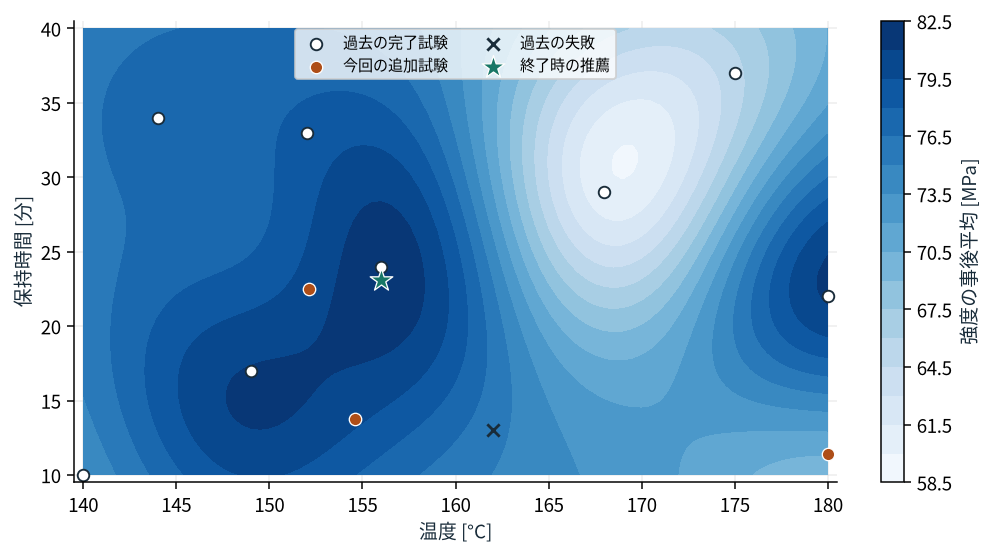

In [3]:
train_x = torch.as_tensor(completed[list(INPUTS)].to_numpy(), dtype=DTYPE)
train_y = torch.as_tensor(completed[["value"]].to_numpy(), dtype=DTYPE)
diagnostic_model = SingleTaskGP(train_x, train_y, **model_transforms())
diagnostic_model.fit()
temperatures = torch.linspace(*BOX["temperature_c"], 81)
hold_times = torch.linspace(*BOX["hold_min"], 81)
ts, hs = torch.meshgrid(temperatures, hold_times, indexing="xy")
grid = torch.stack((ts, hs), dim=-1).reshape(-1, len(INPUTS))
with torch.no_grad():
    posterior_mean = diagnostic_model.posterior(grid).mean.flatten()
recommended_index = posterior_mean.argmax()
recommendation = grid[recommended_index]
recommendation_mean = posterior_mean[recommended_index].item()

fig, ax = plt.subplots(figsize=(7.25, 4.0), layout="constrained")
contours = ax.contourf(ts, hs, posterior_mean.reshape(ts.shape), levels=14, cmap="Blues")
fig.colorbar(contours, ax=ax, label="強度の事後平均 [MPa]")
ax.scatter(complete_history[INPUTS[0]], complete_history[INPUTS[1]],
           s=38, c="white", edgecolor=INK, label="過去の完了試験")
recent = completed.iloc[len(complete_history):]
ax.scatter(recent[INPUTS[0]], recent[INPUTS[1]], s=44, color=ORANGE,
           edgecolors="white", linewidths=0.7, label="今回の追加試験")
ax.scatter(failed[INPUTS[0]], failed[INPUTS[1]], s=43, c=INK,
           marker="x", label="過去の失敗")
ax.scatter(*recommendation, marker="*", color=GREEN, edgecolors="white",
           linewidths=0.7, s=160, label="終了時の推薦", zorder=5)
ax.set(xlabel="温度 [°C]", ylabel="保持時間 [分]")
ax.legend(loc="upper center", ncol=2, fontsize=8)
ax.set(xlim=(139.5, 180.5), ylim=(9.5, 40.5))
save_figure(fig, "ch10_material_recipe")

# Measurements held out from the 3-query optimization budget.
baseline = torch.tensor([148.0, 20.0], dtype=DTYPE)
confirmation_plan = torch.stack((baseline, recommendation))
confirm_generator = torch.Generator().manual_seed(SEED + 102)
confirm = measure(confirmation_plan.expand(4, -1, -1), confirm_generator)
checks = pd.DataFrame(confirm.numpy(), columns=["baseline_mpa", "recommended_mpa"])
checks.index = pd.RangeIndex(1, 5, name="replicate")
checks.to_csv(data / "ch10_confirmation.csv")
print(checks.to_string(float_format=lambda x: f"{x:.2f}"))

## 10.4 1件の最大値と確認試験の平均を読む

左の図は完了試験だけを数えた強度履歴です。右の図では、現行条件と推薦条件をそれぞれ4件測りました。この8件は学習・推薦に使いません。横棒は4件の平均です。繰り返しが少ないので、回を変えたときに同じ平均差が得られるとは限りません。

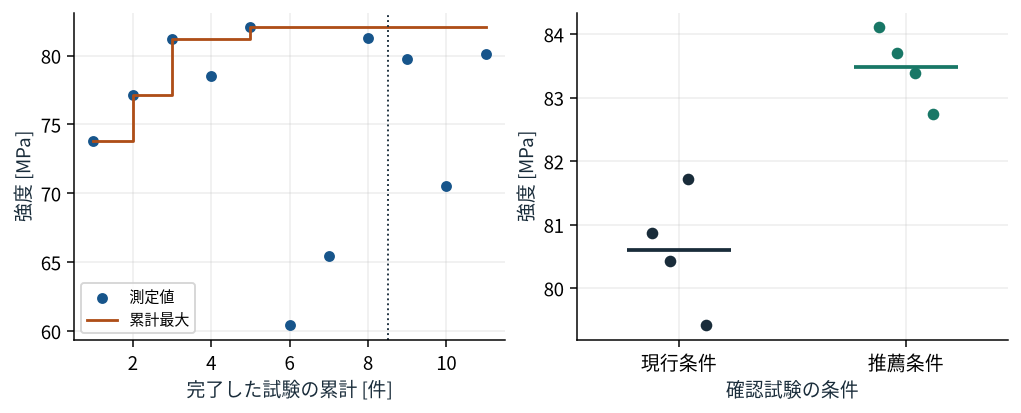

In [4]:
observed = completed["value"].to_numpy()
best_so_far = completed["value"].cummax().to_numpy()
counts = range(1, len(completed) + 1)
fig, axes = plt.subplots(1, 2, figsize=(7.45, 2.95), layout="constrained")
left, right = axes
left.scatter(counts, observed, color=BLUE, label="測定値", s=23)
left.step(counts, best_so_far, where="post", color=ORANGE, label="累計最大")
left.axvline(8.5, color=INK, linestyle=":", linewidth=1)
left.set(xlabel="完了した試験の累計 [件]", ylabel="強度 [MPa]")
left.legend(loc="lower left", fontsize=8)
for index, (column, color) in enumerate(zip(checks, (INK, GREEN))):
    values = checks[column]
    right.scatter([index - .12, index - .04, index + .04, index + .12],
                  values, color=color, s=27)
    right.hlines(values.mean(), index - .23, index + .23, color=color, linewidth=2)
right.set(xlabel="確認試験の条件", ylabel="強度 [MPa]", xlim=(-.45, 1.45))
right.set_xticks([0, 1], ["現行条件", "推薦条件"])
save_figure(fig, "ch10_results_confirmation")

metrics = {
    "history_complete": len(complete_history), "history_failed": len(failed),
    "new_trials": [
        {"temperature": row.temperature_c, "hold": row.hold_min, "strength": row.value}
        for row in recent.itertuples(index=False)
    ],
    "historical_best": float(complete_history["value"].max()),
    "best_observed": best.value, "best_setting": dict(best.params),
    "posterior_mean_at_recommendation": recommendation_mean,
    "recommendation": recommendation.tolist(), "baseline": baseline.tolist(),
    "confirmation": confirm.tolist(), "confirmation_means": confirm.mean(dim=0).tolist(),
}
(QUALITY / "ch10_metrics.json").write_text(json.dumps(metrics, indent=2) + chr(10), encoding="utf-8")